In [10]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from haptools.data import GenotypesTR, GenotypesVCF

# NOTE Important so when loading figures into illustrator the text is seen as text
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42 

# STR Genotypes
chrom = 'chr3' #'chr10' #for KIAA1274 # chr 3 for EFHB
metadata_file = "/storage/mlamkin/workspace/TWAS-str/igsr-geuvadis.tsv"
association_results = f"/storage/mlamkin/data/NonLinearSTRExpression/Geuvadis_nonlinear_associations/gene_expr_{chrom}_nonlinear_associations.tab"
# TODO update association results so that we can give a list of TR chrom and start to plot the strat plots
header_file = "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/train_data/EUR_normalized_and_filtered_hg38.csv"
expr_file = "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/train_data/EUR_normalized_filtered_final_residuals_hg38.csv"
snp_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/SNP_vcfs/SNP_{chrom}_filtered.vcf.gz"
str_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/STR_vcfs/ensemble_{chrom}_filtered.vcf.gz"

## Stratification Plots

In [8]:
def filter_maf(gts, threshold=0.1):
    # filter maf 
    num_strands = 2 * gts.data.shape[0]
    common_variants = np.zeros((gts.data.shape[1],)).astype(np.bool_)
    # NOTE Uses Heterozygosity measure (1 - sum_i (freqs_i^2)) instead of MAF
    for variant in range(gts.data.shape[1]):
        v_data = gts.data[:, variant, :2]
        alleles, counts = np.unique(v_data, return_counts=True)
        sum_freq_sq = np.sum(np.square(counts/num_strands))
        heterozygosity = 1 - sum_freq_sq
        common_variants[variant] = heterozygosity > threshold
    gts.data = gts.data[:,common_variants,:]
    gts.variants = gts.variants[common_variants]
    return gts

def prepare_header_data(header_file, chrom=None, gene=None):
    # Collect samples names and gene names from original expression file EUR_normalized_and_filtered_hg38.csv
    header_data = np.loadtxt(header_file, delimiter="\t", dtype=str)
    eur_samples = list(header_data[0][5:])
    all_genes = header_data[1:,3]

    if gene:
        genes = [gene]
    elif chrom:
        genes = header_data[header_data[:,0] == chrom, 3]
    else:
        genes = header_data[1:,3]
    del header_data

    return eur_samples, all_genes, genes

def collect_gene_region(gene_name, dist):
    """
    Grab region spanning gene with a distance upstream and downstream from 
    gene region of length dist.
    eg. gene coordinates are chr10:1000000-1010000 and dist is 200kb
        region = chr10:800000-1210000

    Parameters
    ----------
    gene_name: str
        Name of gene to collect coordinates from header file
    dist: float
        Distance in kilobases upstream and downstream of gene to collect SNPs/STRs from

    Returns
    -------
    chrom: str
        chromosome of region used for grabbing correct file. eg. chr10
    region: str
        region to collect SNPs and STRs from eg. chr10:800000-1210000
    """
    header_data = np.loadtxt(header_file, delimiter="\t", dtype=str)[1:,:5]
    gene_data = header_data[header_data[:,3] == gene_name].flatten()
    chrom = gene_data[0]
    cis_dist = dist*1000
    region = f"{chrom}:{max(int(gene_data[2]) - cis_dist, 1)}-{int(gene_data[2]) + cis_dist}"
    return chrom, region

def prepare_gene_data(
    expr_file,
    str_file,
    gene_name,
    genes,
    samples,
    region=None,
    delimiter=" ",
    het_thresh=0.1,
    str_variants=None,
):
    # NOTE gene expression data normalized, filtered, and PEER factor residuals removed
    expr_data = np.loadtxt(expr_file, delimiter=delimiter, dtype=np.float32)
    gene_expr_data = expr_data[:, genes == gene_name].flatten()

    # Load STR Genotypes
    str_gts = GenotypesTR(str_file, vcftype='hipstr')
    str_gts.read(region=region, samples=samples, variants=str_variants)
    str_gts = filter_maf(str_gts, het_thresh)
    str_gts.subset(samples=samples, inplace=True)

    assert list(str_gts.samples) == samples

    return gene_expr_data, str_gts

def collect_sig_strs(association_results):
    # Load association results and find where nonlinear sig and linear not sig
    # Linear p at position 7 (for 0 based) Quad p at -2
    assoc_res = np.loadtxt(association_results, delimiter="\t", dtype=str)[1:,:]
    tot_test = assoc_res.shape[0]
    linear_p = np.array(assoc_res[:, 7]).astype(np.float32) * tot_test
    assoc_res = assoc_res[linear_p >= 0.05, :]
    quad_p = np.array(assoc_res[:, -2]).astype(np.float32) * tot_test
    assoc_res = assoc_res[quad_p < 0.05, :]

    return assoc_res

def GetKeepSamplesAlleles(locus_str, gene_expr, mincount):
    """
    locus_str: np.array
        2D genotype array of a single variant samples x strand 
    mincount: int
        Minimum number of each allele that must be present otherwise removed
    """
    # Filter all alleles with unique count < mincount
    uniq, counts = np.unique(locus_str, return_counts=True)
    remove_alleles = uniq[counts < mincount]
    filtered_alleles = np.all(np.isin(locus_str, remove_alleles, invert=True), axis=1)        
    locus_str = locus_str[filtered_alleles,:]
    gene_expr = gene_expr[filtered_alleles]

    return locus_str, gene_expr

def solo_strat_plot(alternate_alleles, lasso_hap_trend, assoc_hap_trend, y_int, mean_expr, boxplot_expr, allele, str_info):
    fig, ax = plt.subplots()
    fig.set_figheight(6)
    fig.set_figwidth(6)
    #ax.plot(alternate_alleles, lasso_hap_trend, 'o-', color='b', label='Lasso Trend')

    # Geuvadis learned association: gene_expr = -5.493208812987814 (X1+X2) + 0.2730153323863306 (X1**2+X2**2)
    #assoc_hap_trend = 0.273015 * (allele**2 + np.square(alternate_alleles)) - 5.4932 * (allele + alternate_alleles) - y_int
    # Trend for EFHB
    assoc_hap_trend = -0.08191283341032415 * (allele**2 + np.square(alternate_alleles)) + 1.4489031822294054 * (allele + alternate_alleles) - y_int

    # Plot trend from lasso regression models
    ax.plot(alternate_alleles, assoc_hap_trend, 'o-', color='g', label='Geuvadis Association')

    # Boxplot version
    ax.boxplot(boxplot_expr, positions=alternate_alleles, tick_labels=alternate_alleles)

    # Plot number of samples above box plots
    for box_ind, box_expr in enumerate(boxplot_expr):
        ax.annotate(f"{len(box_expr)}", (alternate_alleles[box_ind]-.05, max(box_expr)+0.1))

    # Plot alleles and mean gene expression
    ax.plot(np.array(alternate_alleles), mean_expr, 'o-', label="Mean Expression")
    ax.set_xlabel("Allele 2")
    ax.set_ylabel("Mean Expression")
    ax.legend(bbox_to_anchor=(1.5,1), title="Allele 1", loc='upper right')
    ax.set_title(f"Gene {str_info[0].split('.')[0]} STR pos {str_info[3]} Constant Allele {allele}", pad=20)
    ax.set_ylim((-2,2))
    fig.savefig(f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/{str_info[0].split('.')[0]}_{str_info[3]}_allele_{allele}_strat_plot.pdf", bbox_inches='tight')
    return

def stratification_plot(str_info, str_gts, gene_expr, solo_plot_allele=None):
    # sort along cols (sorting along rows doesn't do it by the pairs but by values)
    str_gts = np.sort(str_gts, axis=1)
    str_linear_gts = np.sum(str_gts, axis=1)
    str_nonlinear_gts = np.sum(np.square(str_gts), axis=1)
    str_all_gts = np.column_stack((str_linear_gts, str_nonlinear_gts))    
    
    # standardize all data
    X_scaler = StandardScaler()
    norm_gts = X_scaler.fit_transform(str_all_gts)
    
    # Estimate the y-intercept for KIAA1274 using y_int = gene expr mean - (lin_coeff * norm_str_lin_gts + nonlin_coeff * str_nonlinear_gts)
    # lin_coeff = -5.493208812987814, nonlin_coeff = 0.2730153323863306
    # NOTE the nonlinear GTs are not normalized because we didn't do that when running association tests
    #y_intercept = np.mean(gene_expr) + 5.4932*(np.mean(norm_gts[:,0])) - 0.273015*(np.mean(str_nonlinear_gts))
    # EFHB y_intercept lin_coeff = - 1.4489031822294054 quad_coeff = 0.08191283341032415
    y_intercept = np.mean(gene_expr) - 1.4489031822294054*np.mean(norm_gts[:,0]) + 0.08191283341032415*(np.mean(str_nonlinear_gts))

    # key is sample alleles, value is an array of linear normalized gts and nonlinear normalized gts
    allele_mapping = {}
    for allele_ind, allele_pair in enumerate(str_gts):
        allele_mapping[f'[{allele_pair[0]} {allele_pair[1]}]'] = norm_gts[allele_ind]

    # Flatten all alleles and grab all unique ones
    all_unique_alleles = np.unique(str_gts.flatten())

    # Figure out if one of the alleles only appears in one pair then remove that from the plot
    all_unique_allele_pairs = {}
    for allele_ind, allele in enumerate(all_unique_alleles):
        # Calculate nu
        unique_gts = (str_gts[:,0] == allele) | (str_gts[:,1] == allele)
        alternate_alleles = set()
        for allele_pair in str_gts[unique_gts,:]:
            if allele_pair[0] != allele:
                alternate_alleles.add(allele_pair[0])
            else:
                alternate_alleles.add(allele_pair[1])
        
        # Store alternate alleles if it contains more than 1 allele it pairs with
        if len(alternate_alleles) > 1:
            all_unique_allele_pairs[allele] = alternate_alleles

    unique_alleles = np.array(list(all_unique_allele_pairs.keys()), dtype=np.int32)

    # Calculate number of plots 
    num_plots = np.floor(np.sqrt(unique_alleles.shape[0]))
    first = num_plots
    second = num_plots
    while True:
        if first * second >= unique_alleles.shape[0]:
            break
        if first - second < 1:
            first += 1
        else:
            second += 1

    fig, ax = plt.subplots(int(first), int(second), sharey=True)
    fig.set_figheight(7)
    fig.set_figwidth(9)
    for allele_ind, allele in enumerate(unique_alleles):
        unique_gts = (str_gts[:,0] == allele) | (str_gts[:,1] == allele)

        # Calculate Mean expression and boundaries for plot
        alternate_alleles = np.sort(list(all_unique_allele_pairs[allele]))
        boxplot_expr = []
        expr = []
        min_expr = []
        max_expr = []
        for x_val in alternate_alleles:
            # Calculate mean, min, and max for each unique pairing
            mask = None
            if x_val < allele:
                mask = (str_gts[unique_gts, 0] == x_val) & (str_gts[unique_gts, 1] == allele)
            elif x_val > allele:
                mask = (str_gts[unique_gts, 1] == x_val) & (str_gts[unique_gts, 0] == allele)
            else:
                mask = (str_gts[unique_gts, 0] == x_val) & (str_gts[unique_gts, 1] == allele)

            filtered_expr = (gene_expr[unique_gts])[mask]
            boxplot_expr.append(filtered_expr)
            expr.append(np.mean(filtered_expr))
            std_dev = np.std(filtered_expr)

            # 95% of data included in boundaries
            min_expr.append(expr[-1] - std_dev)
            max_expr.append(expr[-1] + std_dev)

        # Calculate which subplot these values are used in
        y_ind = allele_ind % int(second)
        x_ind = (allele_ind - y_ind) // int(second)

        ######## Copied code ###########
        # Plot alleles and mean gene expression
        # KIAA haploid trend
        # Normalized calculated by doing on entire sample population then grabbing those normalized with a particular allele pair
        norm_alleles = []
        for hap_allele in alternate_alleles:
            first_allele = np.min([allele, hap_allele])
            second_allele = np.max([allele, hap_allele])
            norm_alleles.append(allele_mapping[f'[{first_allele} {second_allele}]'])

        norm_alleles = np.array(norm_alleles)
        lasso_hap_trend = 0.31078 * np.abs(norm_alleles[:,1])
        # TODO uncomment for KIAA1274
        #ax[x_ind][y_ind].plot(alternate_alleles, lasso_hap_trend, 'o-', color='b', label='Lasso Trend')

        # EFHB TR 19947266 Geuvadis learned association gene_expr = 1.4489031822294054 (X1+X2) + -0.08191283341032415 (X1**2+X2**2)
        #assoc_hap_trend = -0.08191283341032415 * (allele**2 + np.square(alternate_alleles)) + 1.4489031822294054 * (allele + alternate_alleles) - y_intercept
        # KIAA1274 Geuvadis learned association: gene_expr = -5.493208812987814 (X1+X2) + 0.2730153323863306 (X1**2+X2**2)
        #assoc_hap_trend = 0.273015 * (allele**2 + np.square(alternate_alleles)) - 5.4932 * (allele + alternate_alleles) - y_intercept
        #ax[x_ind][y_ind].plot(alternate_alleles, assoc_hap_trend, 'o-', color='g', label='Geuvadis Association')

        # Boxplot version
        ax[x_ind][y_ind].boxplot(boxplot_expr, positions=alternate_alleles, tick_labels=alternate_alleles)

        # Plot number of samples above box plots
        for box_ind, box_expr in enumerate(boxplot_expr):
            ax[x_ind][y_ind].annotate(f"{len(box_expr)}", (alternate_alleles[box_ind]-.05, max(box_expr)+0.15))

        # Plot alleles and mean gene expression
        ax[x_ind][y_ind].plot(np.array(alternate_alleles), expr, 'o-', label=f"Mean Expression")
        #ax[x_ind][y_ind].fill_between(alternate_alleles, min_expr, max_expr, alpha=0.3)
        if x_ind == int(first)-1:
            ax[x_ind][y_ind].set_xlabel("Allele 2")
        if y_ind == 0:
            ax[x_ind][y_ind].set_ylabel("Mean Expression")

        ax[x_ind][y_ind].set_title(f"{allele} Constant")

        if allele == solo_plot_allele:
            solo_strat_plot(
                alternate_alleles, 
                lasso_hap_trend, 
                assoc_hap_trend, 
                y_intercept, 
                expr, 
                boxplot_expr, 
                allele, 
                str_info,
            )
    handles, labels = ax[x_ind][y_ind].get_legend_handles_labels()
    fig.subplots_adjust(hspace=0.5)
    fig.legend(handles=handles, labels=labels, bbox_to_anchor=(1.05,1), loc='upper right')
    fig.suptitle(f"STR pos {str_info[3]} Gene {str_info[0]}")
    fig.savefig(f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/{str_info[0].split('.')[0]}_{str_info[3]}_strat_plot.pdf", bbox_inches='tight')
    return


def allele_heatmap(str_info, str_gts, gene_expr):
    str_gts = np.sort(str_gts, axis=1)
    uniq_alleles = np.unique(str_gts)

    # Create new array where x (row) and y (col) axis indices are allele repeat numbers and values are gene expression average values
    gene_expr_mtx = np.full((len(uniq_alleles), len(uniq_alleles)), np.nan)

    # Collect gene expr values and average
    uniq_pairs = np.unique(str_gts, axis=0)
    for ind, pair in enumerate(uniq_pairs):
        pair_expr = (str_gts[:,0] == pair[0]) & (str_gts[:,1] == pair[1])
        gene_expr_mtx[np.where(uniq_alleles == pair[0]), np.where(uniq_alleles == pair[1])] = np.mean(gene_expr[pair_expr])

    # Setup figure
    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111)

    # Plot heatmap
    cmap = mpl.colormaps.get_cmap('viridis')  # viridis is the default colormap for imshow
    cmap.set_bad(color='white')
    im = ax.imshow(gene_expr_mtx, cmap=cmap, vmin=-1, vmax=1)
    fig.colorbar(im)

    # Format Axes for labeling with proper alleles
    ax.xaxis.set_ticks(np.arange(0, len(uniq_alleles)))
    ax.yaxis.set_ticks(np.arange(0, len(uniq_alleles)))
    ax.set_xticklabels(uniq_alleles)
    ax.set_yticklabels(uniq_alleles)
    ax.set_xlabel("Allele 2 Repeat Count")
    ax.set_ylabel("Allele 1 Repeat Count")
    ax.set_title(f"STR pos {str_info[3]} Gene {str_info[0]}")
    return

Generating plots for 242 significant STRs
chr3:46837755-46837757


Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!


chr3:46950025-46950027


Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!


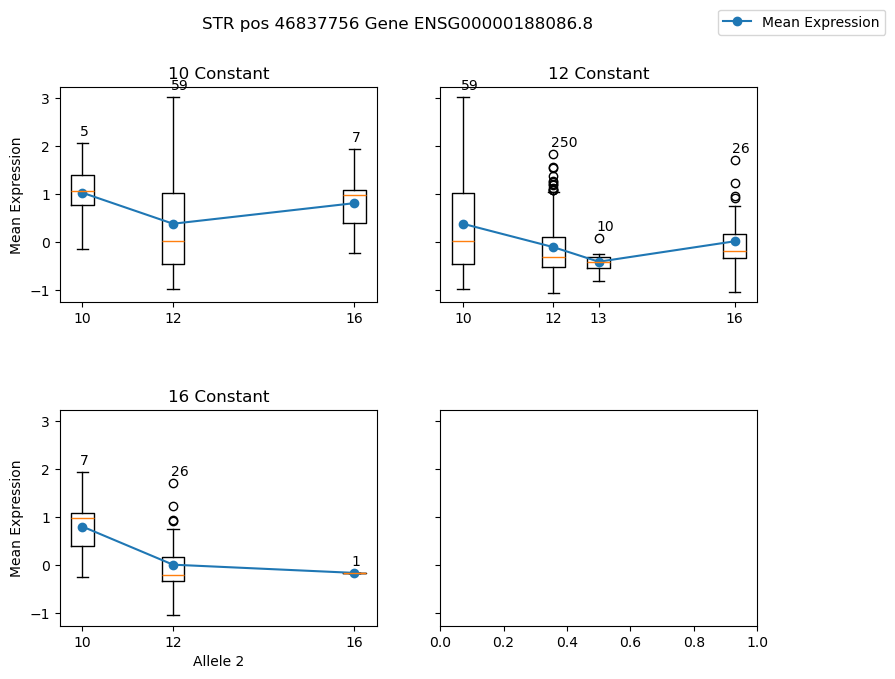

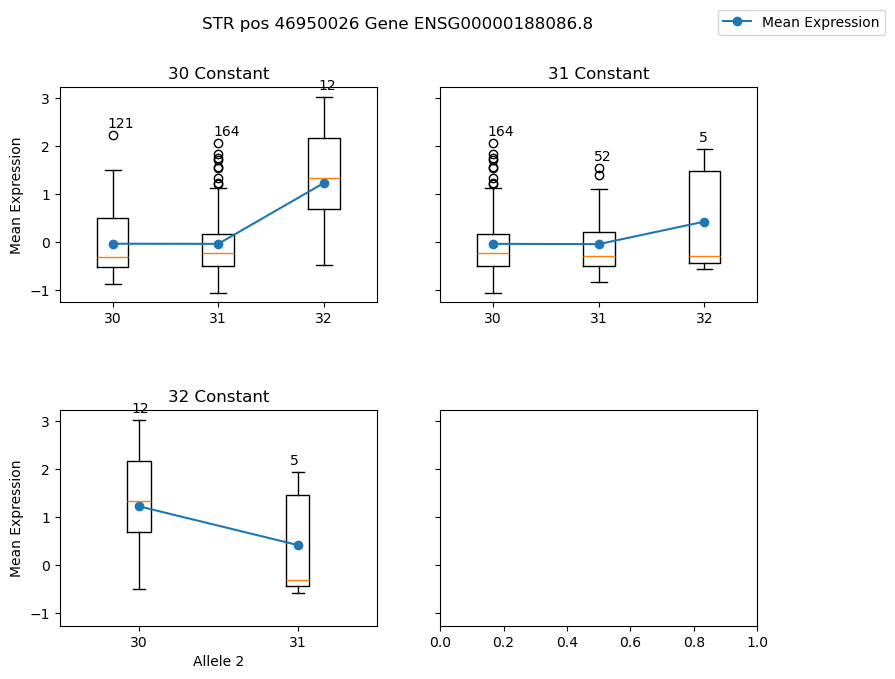

In [11]:
# Minimum number of unique str alleles that must be present to plot
min_unique_alleles = 1

# Load samples, gene names to iterate over, and covariates for calculating residuals
eur_samples, all_genes, gene_names = prepare_header_data(header_file, f"chr{chrom}")

# Select STRs to make a plot
gene_dist = 500
sig_strs = collect_sig_strs(association_results)

# Iterate over all significant STRs
print(f"Generating plots for {sig_strs.shape[0]} significant STRs")
for sig_str in sig_strs:
    gene_name = sig_str[0].split('.')[0]
    gene_id = sig_str[0]
    if not gene_name == 'ENSG00000163576': continue # This is for EFHB
    if not sig_str[3] == '19947266': continue
    #if not gene_name == 'ENSG00000107719': continue # This is for KIAA1274
    #print(sig_str[3])

    # Load gene expression and all str_gts in the region
    # NOTE gene expression data normalized, filtered, and PEER factor residuals removed
    gene_region = f"{chrom}:{int(sig_str[3])-1}-{int(sig_str[3])+1}"
    print(gene_region)
    gene_expr_res, all_str_gts = prepare_gene_data(
        expr_file,
        str_file,
        gene_id,
        all_genes,
        eur_samples,
        region=gene_region,
    )

    str_gts = np.squeeze(all_str_gts.data[:, all_str_gts.variants["pos"] == int(sig_str[3]), :2])
    if len(str_gts.shape) == 3:
        str_gts = np.squeeze(str_gts[:, 0, :])
    invalid_alleles = np.all(str_gts < 254, axis=1)
    str_gts = str_gts[invalid_alleles,:]
    filtered_gene_expr_res = gene_expr_res[invalid_alleles]

    # Filter outlier alleles (seen < 3 times)
    str_gts, filtered_gene_expr_res = GetKeepSamplesAlleles(
        str_gts, filtered_gene_expr_res, 3
    )

    if len(np.unique(str_gts)) < min_unique_alleles:
        continue

    stratification_plot(sig_str, str_gts, filtered_gene_expr_res)# for EFHB solo_plot_allele=6) # ,solo_plot_allele=10) #For KIAA1274
    #allele_heatmap(sig_str, str_gts, filtered_gene_expr_res)


In [ ]:
#### EFHB Plot ####

## STRs vs Geuvadis Gene Expression

In [5]:
def plot_str_expr(strs, gene_expr, str_name, gene):
    title = f"{str_name} vs {gene}"
    fig = plt.figure()
    ax = fig.add_subplot(1,1,1)
    ax.set_title(title)
    ax.set_xlabel("STR Allele1 + Allele2 Genotype")
    ax.set_ylabel("Gene Expression")
    ax.scatter(strs, gene_expr)
    # Group STRs and average the expr to plot a line
    unique_gts = np.unique(strs)
    mean_expr = np.zeros(len(unique_gts))
    for ind, gt in enumerate(unique_gts):
        mean_expr[ind] = np.mean(gene_expr[strs == gt])
    ax.plot(unique_gts, mean_expr, color='k')
    return

The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
The current variant in the VCF only has one allele per sample.
The current variant in the VCF only has one allele per sample.
The current variant in the VCF only has one allele per sample.


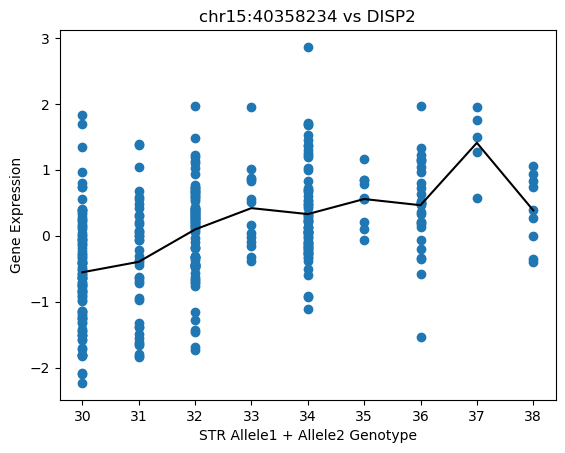

In [6]:
# Try pre-regressed values
#expr_file = "/storage/mlamkin/workspace/TWAS-str/EUR_converted_expr_spaces_hg38.csv"
# Use final gene expr residuals
expr_file = "/storage/mlamkin/workspace/TWAS-str/EUR_normalized_filtered_final_residuals_hg38.csv"
delimiter = " "

# Load samples, gene names to iterate over, and covariates for calculating residuals
target_gene = "ENSG00000140323.4" # DISP2
gene_name = "DISP2"
eur_samples, all_genes, gene_names = prepare_header_data(header_file, "chr15")

# Grab one or a list of STRs GTs given their chr, start
target_strs = [
    ['chr15', 40358234],
]

# Iterate over all significant STRs
for target_str in target_strs:
    gene_region = f"{target_str[0]}:{target_str[1]}"
    gene_expr_res, str_gts = prepare_gene_data(
        expr_file,
        str_file,
        target_gene,
        all_genes,
        eur_samples,
        delimiter=delimiter,
        region=gene_region,
    )
    str_gts = np.squeeze(str_gts.data[:, str_gts.variants["pos"] == target_str[1], :])[:, :2]

    invalid_alleles = np.all(str_gts < 254, axis=1)
    str_gts = str_gts[invalid_alleles,:]
    filtered_gene_expr_res = gene_expr_res[invalid_alleles]

    # Filter outlier alleles (seen < 3 times)
    str_gts, filtered_gene_expr_res = GetKeepSamplesAlleles(
        str_gts, filtered_gene_expr_res, 3
    )
    str_gts = np.sum(str_gts, axis=1)
    str_name = f"{target_str[0]}:{target_str[1]}"
    
    plot_str_expr(str_gts, filtered_gene_expr_res, str_name, gene_name)

## Plot SNP Relationships

['HG00097', 'HG00099', 'HG00100', 'HG00101', 'HG00102', 'HG00103', 'HG00105', 'HG00106', 'HG00108', 'HG00109', 'HG00110', 'HG00111', 'HG00112', 'HG00114', 'HG00115', 'HG00116', 'HG00117', 'HG00118', 'HG00119', 'HG00120', 'HG00121', 'HG00122', 'HG00123', 'HG00125', 'HG00126', 'HG00127', 'HG00128', 'HG00129', 'HG00130', 'HG00131', 'HG00132', 'HG00133', 'HG00136', 'HG00137', 'HG00138', 'HG00139', 'HG00141', 'HG00142', 'HG00143', 'HG00145', 'HG00146', 'HG00148', 'HG00149', 'HG00150', 'HG00151', 'HG00154', 'HG00155', 'HG00157', 'HG00158', 'HG00159', 'HG00160', 'HG00171', 'HG00173', 'HG00174', 'HG00176', 'HG00177', 'HG00178', 'HG00179', 'HG00180', 'HG00181', 'HG00182', 'HG00183', 'HG00185', 'HG00186', 'HG00187', 'HG00188', 'HG00189', 'HG00231', 'HG00232', 'HG00233', 'HG00234', 'HG00235', 'HG00236', 'HG00238', 'HG00239', 'HG00240', 'HG00242', 'HG00243', 'HG00244', 'HG00245', 'HG00246', 'HG00250', 'HG00251', 'HG00252', 'HG00253', 'HG00255', 'HG00256', 'HG00257', 'HG00258', 'HG00259', 'HG00260'

The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!


('HG00097', 'HG00099', 'HG00100', 'HG00101', 'HG00102', 'HG00103', 'HG00105', 'HG00106', 'HG00108', 'HG00109', 'HG00110', 'HG00111', 'HG00112', 'HG00114', 'HG00115', 'HG00116', 'HG00117', 'HG00118', 'HG00119', 'HG00120', 'HG00121', 'HG00122', 'HG00123', 'HG00125', 'HG00126', 'HG00127', 'HG00128', 'HG00129', 'HG00130', 'HG00131', 'HG00132', 'HG00133', 'HG00136', 'HG00137', 'HG00138', 'HG00139', 'HG00141', 'HG00142', 'HG00143', 'HG00145', 'HG00146', 'HG00148', 'HG00149', 'HG00150', 'HG00151', 'HG00154', 'HG00155', 'HG00157', 'HG00158', 'HG00159', 'HG00160', 'HG00171', 'HG00173', 'HG00174', 'HG00176', 'HG00177', 'HG00178', 'HG00179', 'HG00180', 'HG00181', 'HG00182', 'HG00183', 'HG00185', 'HG00186', 'HG00187', 'HG00188', 'HG00189', 'HG00231', 'HG00232', 'HG00233', 'HG00234', 'HG00235', 'HG00236', 'HG00238', 'HG00239', 'HG00240', 'HG00242', 'HG00243', 'HG00244', 'HG00245', 'HG00246', 'HG00250', 'HG00251', 'HG00252', 'HG00253', 'HG00255', 'HG00256', 'HG00257', 'HG00258', 'HG00259', 'HG00260'

The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!


('HG00097', 'HG00099', 'HG00100', 'HG00101', 'HG00102', 'HG00103', 'HG00105', 'HG00106', 'HG00108', 'HG00109', 'HG00110', 'HG00111', 'HG00112', 'HG00114', 'HG00115', 'HG00116', 'HG00117', 'HG00118', 'HG00119', 'HG00120', 'HG00121', 'HG00122', 'HG00123', 'HG00125', 'HG00126', 'HG00127', 'HG00128', 'HG00129', 'HG00130', 'HG00131', 'HG00132', 'HG00133', 'HG00136', 'HG00137', 'HG00138', 'HG00139', 'HG00141', 'HG00142', 'HG00143', 'HG00145', 'HG00146', 'HG00148', 'HG00149', 'HG00150', 'HG00151', 'HG00154', 'HG00155', 'HG00157', 'HG00158', 'HG00159', 'HG00160', 'HG00171', 'HG00173', 'HG00174', 'HG00176', 'HG00177', 'HG00178', 'HG00179', 'HG00180', 'HG00181', 'HG00182', 'HG00183', 'HG00185', 'HG00186', 'HG00187', 'HG00188', 'HG00189', 'HG00231', 'HG00232', 'HG00233', 'HG00234', 'HG00235', 'HG00236', 'HG00238', 'HG00239', 'HG00240', 'HG00242', 'HG00243', 'HG00244', 'HG00245', 'HG00246', 'HG00250', 'HG00251', 'HG00252', 'HG00253', 'HG00255', 'HG00256', 'HG00257', 'HG00258', 'HG00259', 'HG00260'

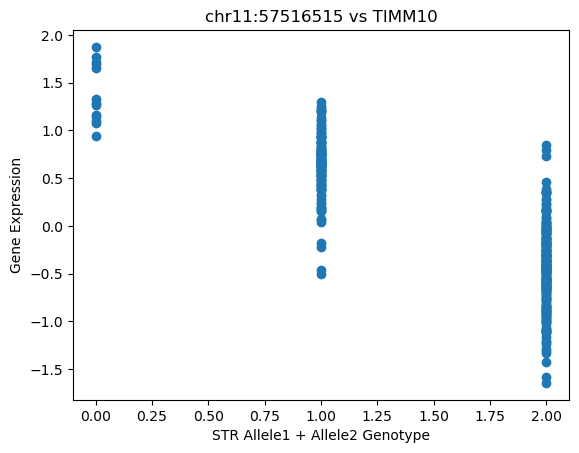

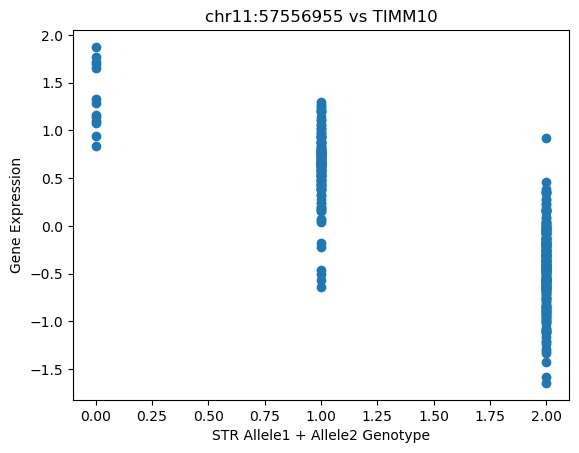

In [7]:
def prepare_gene_data(
    expr_file,
    snp_file,
    gene_name,
    genes,
    samples,
    region=None,
    delimiter=" ",
    het_thresh=0.1,
    snp_variants=None,
):
    # NOTE gene expression data normalized, filtered, and PEER factor residuals removed
    expr_data = np.loadtxt(expr_file, delimiter=delimiter, dtype=np.float32)
    gene_expr_data = expr_data[:, genes == gene_name].flatten()

    # Load Matrices of data, gts located in snp_gts.data and str_gts.data
    # Filter out rare variants
    snp_gts = GenotypesVCF.load(snp_file, samples=samples, variants=snp_variants, region=region)
    snp_gts = filter_maf(snp_gts, het_thresh)
    snp_gts.subset(samples=samples, inplace=True)

    assert list(snp_gts.samples) == samples

    return gene_expr_data, snp_gts


# Use final gene expr residuals
expr_file = "/storage/mlamkin/workspace/TWAS-str/EUR_normalized_filtered_final_residuals_hg38.csv"
delimiter = " "

# Load samples, gene names to iterate over, and covariates for calculating residuals
target_gene = "ENSG00000134809.4"
gene_name = "TIMM10"
eur_samples, all_genes, gene_names = prepare_header_data(header_file, "chr11")

# Grab one or a list of STRs GTs given their chr, start
target_vars = [
    ['chr11', 57516515],
    ['chr11', 57556955],
]

# Iterate over all significant STRs
for target_var in target_vars:
    gene_region = f"{target_var[0]}:{target_var[1]}-{target_var[1]+1}"
    gene_expr_res, snp_gts = prepare_gene_data(
        expr_file,
        snp_file,
        target_gene,
        all_genes,
        eur_samples,
        delimiter=delimiter,
        region=gene_region,
    )
    snp_gts = np.sum(snp_gts.data, axis=2)
    snp_name = f"{target_var[0]}:{target_var[1]}"
    
    plot_str_expr(snp_gts, gene_expr_res, snp_name, gene_name)

## P-Value Validation Chr19

In [26]:
def collect_pvalues(data1, data2):
    # Collect same STR-gene stats and compare in plot
    pvals1 = []
    pvals2 = []
    d1_ind = 0
    d2_ind = 0

    while d1_ind < data1.shape[0] and d2_ind < data2.shape[0]:
        d1_gene = data1[d1_ind, 0]
        d1_pos = int(data1[d1_ind, 1])
        d2_gene = data2[d2_ind, 0]
        d2_pos = int(data2[d2_ind, 1])

        if d1_pos == d2_pos and d1_gene == d2_gene:
            pvals1.append(float(data1[d1_ind, 2]))
            pvals2.append(float(data2[d2_ind, 2]))
            d1_ind += 1
            d2_ind += 1

        if d1_pos < d2_pos:
            d1_ind += 1
            continue

        if d2_pos < d1_pos or d2_gene < d1_gene:
            d2_ind += 1
            continue

        if d1_gene < d2_gene:
            d1_ind += 1
            continue

    return -1*np.log10(pvals1), -1*np.log10(pvals2)

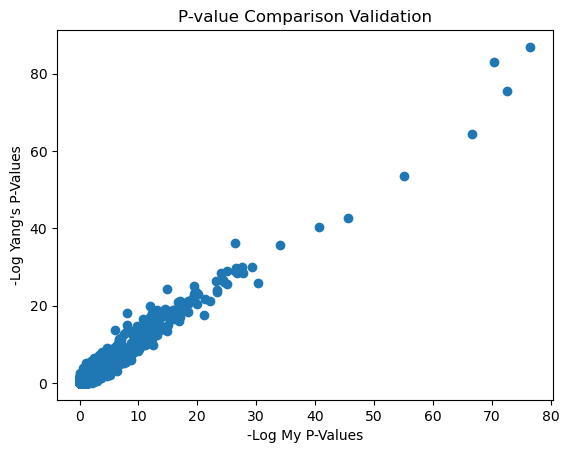

In [27]:
import re

# pvalue files
my_assoc_file = "/storage/mlamkin/data/TWAS-str/Geuvadis_nonlinear_associations/gene_expr_chr19_nonlinear_associations.tab"
yang_assoc_file = "/gymreklab-tscc/yal084_storage/Geuvadis_summary_statistic/updated_ensemble_regression/EUR_eSTR_regression_with_gender_motif_END.csv"

# Load my pvalues and sort by coord
my_assocs = np.loadtxt(my_assoc_file, dtype=str, usecols=(0,3,7))[1:,:]
my_coords = my_assocs[:,1].astype(np.int32)
my_assocs = my_assocs[my_coords.argsort()]

# Load Yangs pvalues, limit to chr19, and sort
chrom = "chr19"
yang_assocs = np.loadtxt(yang_assoc_file, dtype=str, usecols=(0,1,6))[1:,:]
chrom_inds = np.char.find(yang_assocs[:,0], chrom) == 0
yang_assocs = yang_assocs[chrom_inds, :]
yang_coords = yang_assocs[:,1].astype(np.int32)
yang_assocs = yang_assocs[yang_coords.argsort()]
pvals = yang_assocs[:,-1][:, np.newaxis]

# Restructure to Gene name, str start, pvalue
yang_assocs = np.array([re.split("[_|-]", yang_assocs[ind, 0])[1:] for ind in range(yang_assocs.shape[0])])
yang_assocs[:,[1,0]] = yang_assocs[:,[0,1]]
yang_assocs = np.concatenate((yang_assocs, pvals), axis=1)

my_pvals, yang_pvals = collect_pvalues(my_assocs, yang_assocs)

fig = plt.figure()
ax = fig.add_subplot(1,1,1)
ax.set_title("P-value Comparison Validation")
ax.set_xlabel("-Log My P-Values")
ax.set_ylabel("-Log Yang's P-Values")
ax.scatter(my_pvals, yang_pvals)
plt.show()
